In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
import os

print("Current folder:")
print(os.getcwd())

print("\nHome folder:")
print(os.path.expanduser("~"))

print("\nDesktop folders:")
home = os.path.expanduser("~")

for folder in ["Desktop", "OneDrive/Desktop"]:
    path = os.path.join(home, folder)
    print(folder, ":", os.path.exists(path))

    if os.path.exists(path):
        print(os.listdir(path))

Current folder:
d:\Python Programs

Home folder:
C:\Users\HP

Desktop folders:
Desktop : False
OneDrive/Desktop : True
['Anaconda Navigator - Shortcut.lnk', 'Brave.lnk', 'CodeAlpha', 'desktop.ini', 'Excel and Power BI Folder', 'Firefox.exe', 'German Language', 'Power BI Desktop.lnk', 'Python Programs', 'Ravi Bro', 'Self', 'SQL', 'Tableau', 'Typing Master 12.lnk', 'WhatsApp Image 2026-09-07 at 5.56.16 PM.jpeg', 'WhatsApp.lnk']


In [3]:
import os
import pandas as pd

folder_path = r"C:\Users\HP\OneDrive\Desktop\CodeAlpha"

print(os.listdir(folder_path))

['bank', 'bank-additional']


In [4]:
import os

bank_path = r"C:\Users\HP\OneDrive\Desktop\CodeAlpha\bank"

print(os.listdir(bank_path))

['bank-full.csv', 'bank-names.txt', 'bank.csv']


In [5]:
import pandas as pd

file_path = r"C:\Users\HP\OneDrive\Desktop\CodeAlpha\bank\bank-full.csv"

df = pd.read_csv(file_path, sep=";")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [6]:
print(df.shape)

(45211, 17)


In [7]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 8.1 MB


In [9]:
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [12]:
df["job"].value_counts()

job
blue-collar      9732
management       9458
technician       7597
admin.           5171
services         4154
retired          2264
self-employed    1579
entrepreneur     1487
unemployed       1303
housemaid        1240
student           938
unknown           288
Name: count, dtype: int64

In [13]:
df["y"].value_counts()

y
no     39922
yes     5289
Name: count, dtype: int64

In [14]:
(df["y"].value_counts(normalize=True) * 100).round(2)

y
no     88.3
yes    11.7
Name: proportion, dtype: float64

In [15]:
pd.crosstab(df["job"], df["y"])

y,no,yes
job,,
admin.,4540,631
blue-collar,9024,708
entrepreneur,1364,123
housemaid,1131,109
management,8157,1301
retired,1748,516
self-employed,1392,187
services,3785,369
student,669,269


In [16]:
job_subscription = pd.crosstab(df["job"], df["y"], normalize="index") * 100

job_subscription.round(2)

y,no,yes
job,,
admin.,87.80,12.20
blue-collar,92.73,7.27
entrepreneur,91.73,8.27
housemaid,91.21,8.79
management,86.24,13.76
retired,77.21,22.79
self-employed,88.16,11.84
services,91.12,8.88
student,71.32,28.68


In [17]:
df.groupby("y")["age"].mean().round(2)

y
no     40.84
yes    41.67
Name: age, dtype: float64

In [18]:
pd.crosstab(df["marital"], df["y"], normalize="index").mul(100).round(2)

y,no,yes
marital,,
divorced,88.05,11.95
married,89.88,10.12
single,85.05,14.95


In [19]:
pd.crosstab(df["education"], df["y"], normalize="index").mul(100).round(2)

y,no,yes
education,,
primary,91.37,8.63
secondary,89.44,10.56
tertiary,84.99,15.01
unknown,86.43,13.57


In [20]:
pd.crosstab(df["housing"], df["y"], normalize="index").mul(100).round(2)

y,no,yes
housing,,
no,83.3,16.7
yes,92.3,7.7


In [21]:
pd.crosstab(df["loan"], df["y"], normalize="index").mul(100).round(2)

y,no,yes
loan,,
no,87.34,12.66
yes,93.32,6.68


In [22]:
pd.crosstab(df["contact"], df["y"], normalize="index").mul(100).round(2)

y,no,yes
contact,,
cellular,85.08,14.92
telephone,86.58,13.42
unknown,95.93,4.07


In [23]:
pd.crosstab(df["month"], df["y"], normalize="index").mul(100).round(2)

y,no,yes
month,,
apr,80.32,19.68
aug,88.99,11.01
dec,53.27,46.73
feb,83.35,16.65
jan,89.88,10.12
jul,90.91,9.09
jun,89.78,10.22
mar,48.01,51.99
may,93.28,6.72


In [24]:
df.groupby("y")["campaign"].mean().round(2)

y
no     2.85
yes    2.14
Name: campaign, dtype: float64

In [25]:
df.groupby("y")["duration"].mean().round(2)

y
no     221.18
yes    537.29
Name: duration, dtype: float64

In [26]:
pd.crosstab(df["poutcome"], df["y"], normalize="index").mul(100).round(2)

y,no,yes
poutcome,,
failure,87.39,12.61
other,83.32,16.68
success,35.27,64.73
unknown,90.84,9.16


In [27]:
df[["age", "balance", "duration", "campaign", "pdays", "previous"]].describe()

,age,balance,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,4918.000000,63.000000,871.000000,275.000000


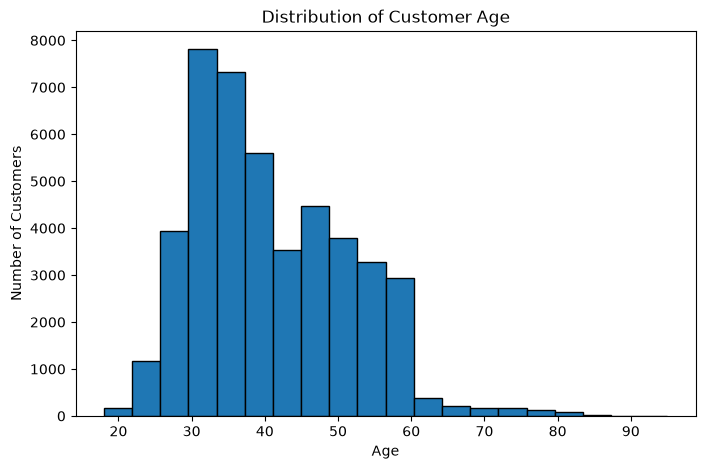

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df["age"], bins=20, edgecolor="black")
plt.title("Distribution of Customer Age")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.show()

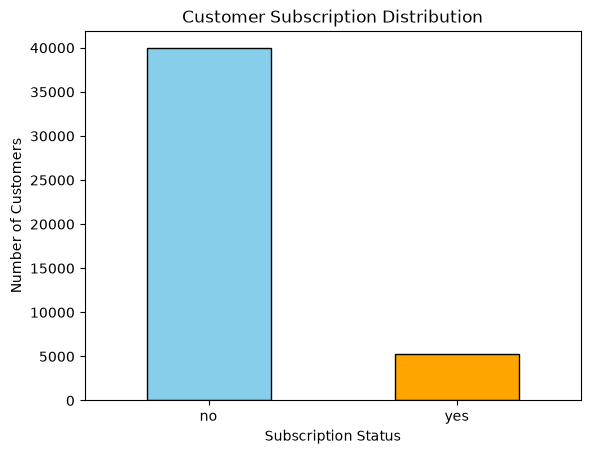

In [29]:
df["y"].value_counts().plot(
    kind="bar",
    color=["skyblue", "orange"],
    edgecolor="black"
)

plt.title("Customer Subscription Distribution")
plt.xlabel("Subscription Status")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

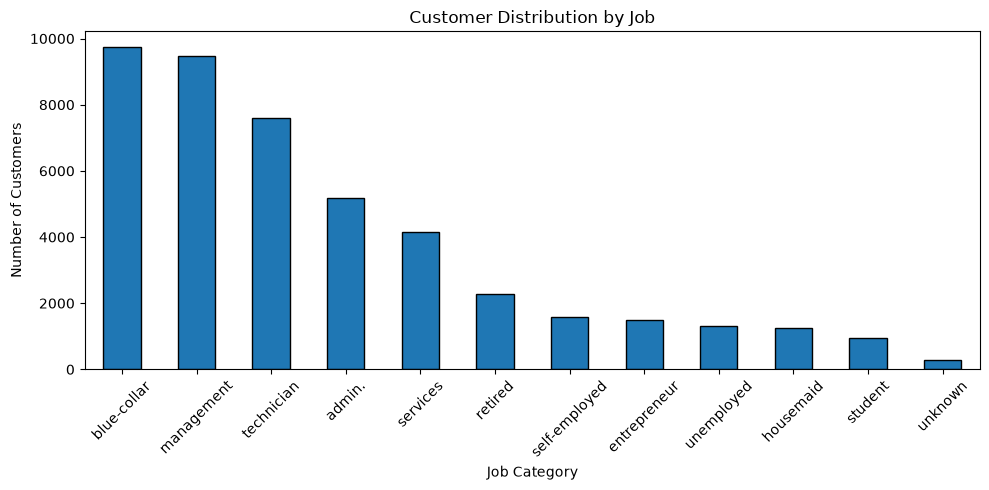

In [30]:
plt.figure(figsize=(10, 5))

df["job"].value_counts().plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Customer Distribution by Job")
plt.xlabel("Job Category")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

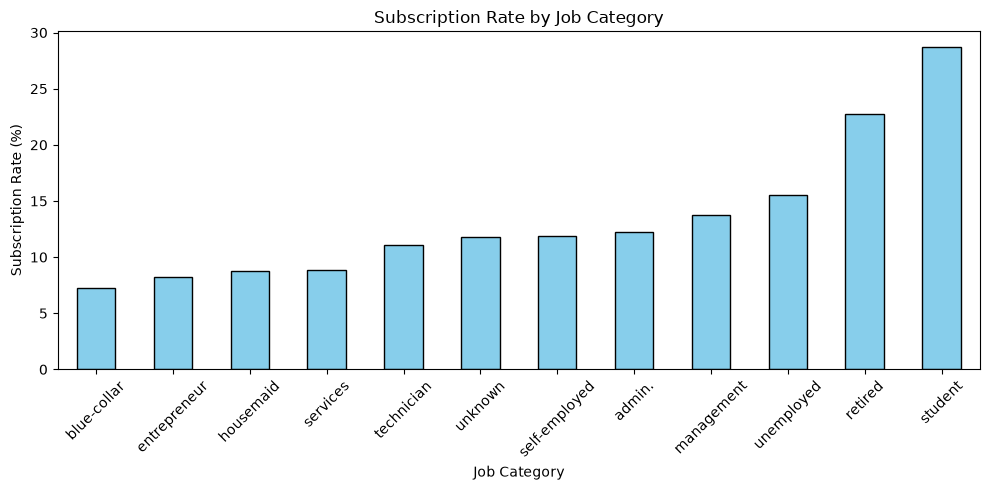

In [31]:
job_subscription["yes"].sort_values().plot(
    kind="bar",
    figsize=(10, 5),
    color="skyblue",
    edgecolor="black"
)

plt.title("Subscription Rate by Job Category")
plt.xlabel("Job Category")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

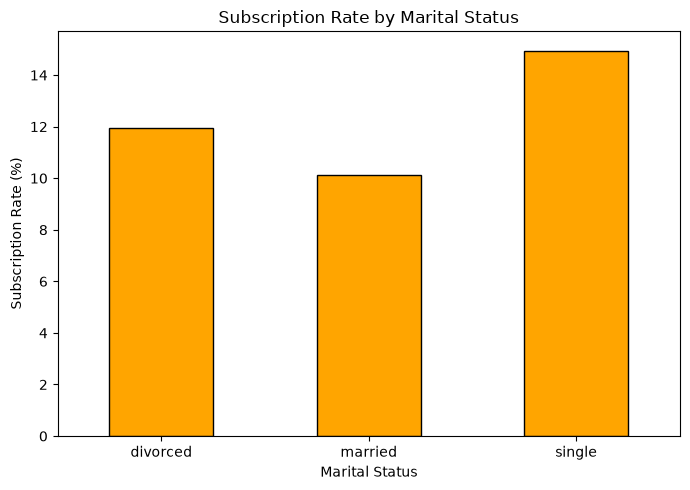

In [32]:
marital_subscription = pd.crosstab(
    df["marital"],
    df["y"],
    normalize="index"
) * 100

marital_subscription["yes"].plot(
    kind="bar",
    figsize=(7, 5),
    color="orange",
    edgecolor="black"
)

plt.title("Subscription Rate by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

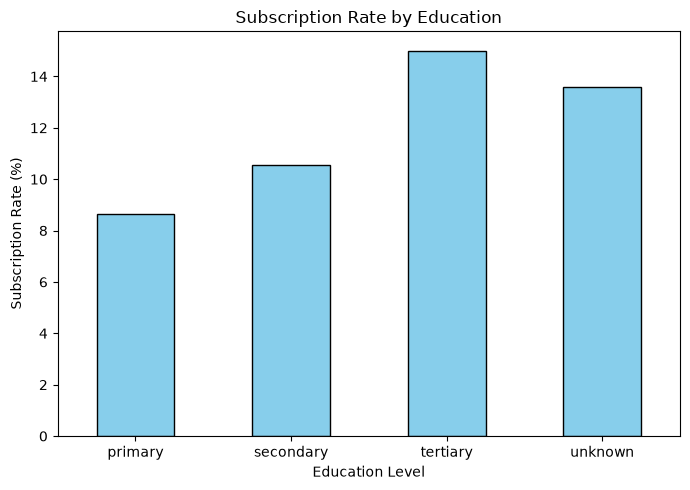

In [33]:
education_subscription = pd.crosstab(
    df["education"],
    df["y"],
    normalize="index"
) * 100

education_subscription["yes"].plot(
    kind="bar",
    figsize=(7, 5),
    color="skyblue",
    edgecolor="black"
)

plt.title("Subscription Rate by Education")
plt.xlabel("Education Level")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

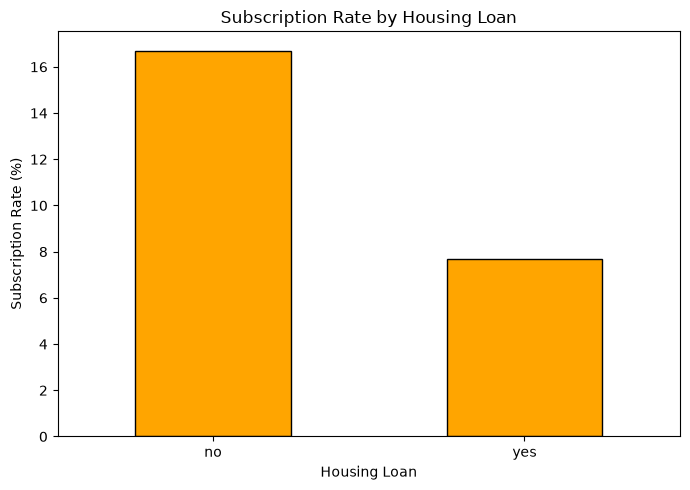

In [34]:
housing_subscription = pd.crosstab(
    df["housing"],
    df["y"],
    normalize="index"
) * 100

housing_subscription["yes"].plot(
    kind="bar",
    figsize=(7, 5),
    color="orange",
    edgecolor="black"
)

plt.title("Subscription Rate by Housing Loan")
plt.xlabel("Housing Loan")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

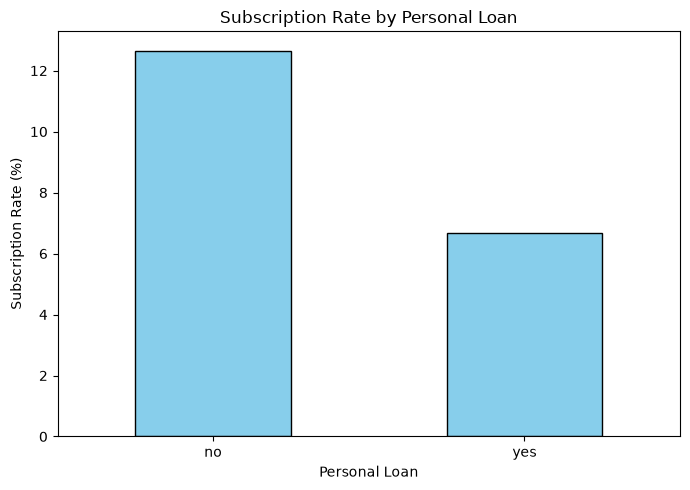

In [35]:
loan_subscription = pd.crosstab(
    df["loan"],
    df["y"],
    normalize="index"
) * 100

loan_subscription["yes"].plot(
    kind="bar",
    figsize=(7, 5),
    color="skyblue",
    edgecolor="black"
)

plt.title("Subscription Rate by Personal Loan")
plt.xlabel("Personal Loan")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

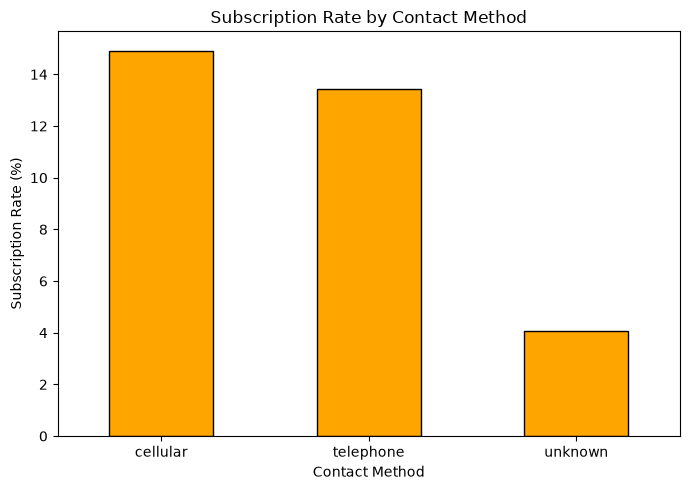

In [36]:
contact_subscription = pd.crosstab(
    df["contact"],
    df["y"],
    normalize="index"
) * 100

contact_subscription["yes"].plot(
    kind="bar",
    figsize=(7, 5),
    color="orange",
    edgecolor="black"
)

plt.title("Subscription Rate by Contact Method")
plt.xlabel("Contact Method")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

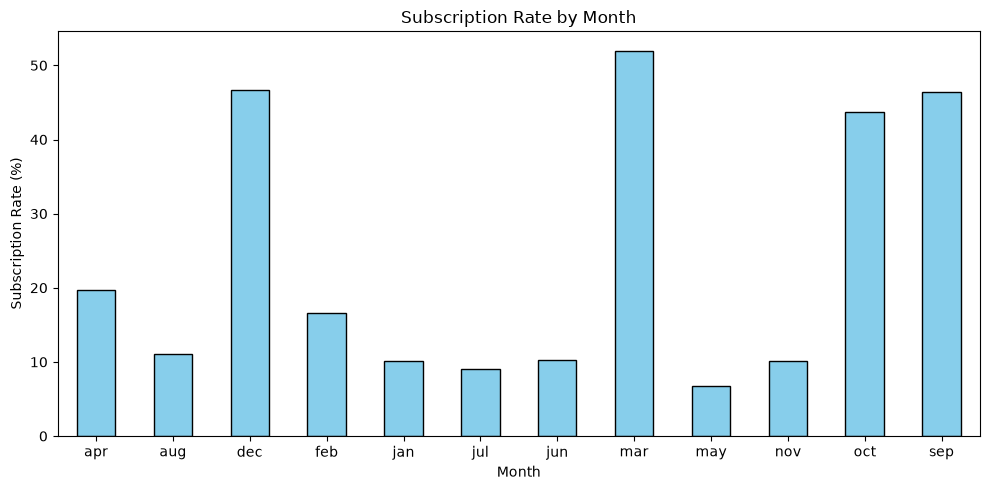

In [37]:
month_subscription = pd.crosstab(
    df["month"],
    df["y"],
    normalize="index"
) * 100

month_subscription["yes"].plot(
    kind="bar",
    figsize=(10, 5),
    color="skyblue",
    edgecolor="black"
)

plt.title("Subscription Rate by Month")
plt.xlabel("Month")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

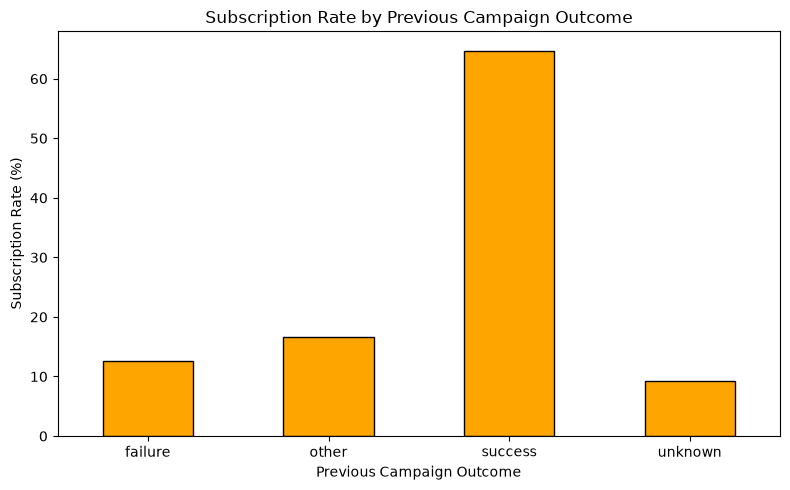

In [38]:
poutcome_subscription = pd.crosstab(
    df["poutcome"],
    df["y"],
    normalize="index"
) * 100

poutcome_subscription["yes"].plot(
    kind="bar",
    figsize=(8, 5),
    color="orange",
    edgecolor="black"
)

plt.title("Subscription Rate by Previous Campaign Outcome")
plt.xlabel("Previous Campaign Outcome")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

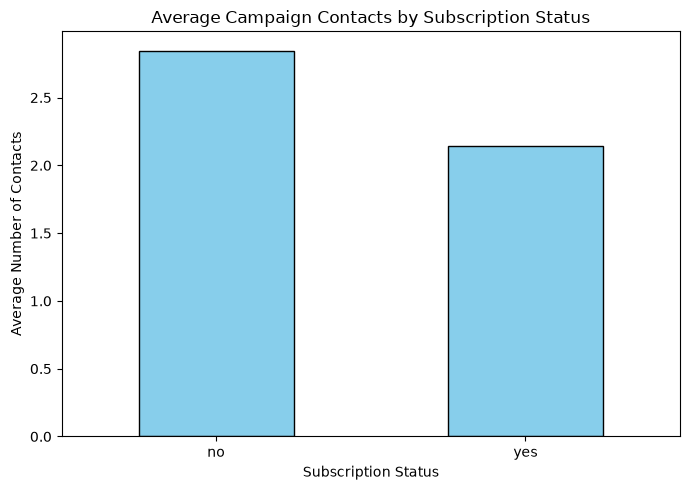

In [39]:
campaign_average = df.groupby("y")["campaign"].mean()

campaign_average.plot(
    kind="bar",
    figsize=(7, 5),
    color="skyblue",
    edgecolor="black"
)

plt.title("Average Campaign Contacts by Subscription Status")
plt.xlabel("Subscription Status")
plt.ylabel("Average Number of Contacts")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

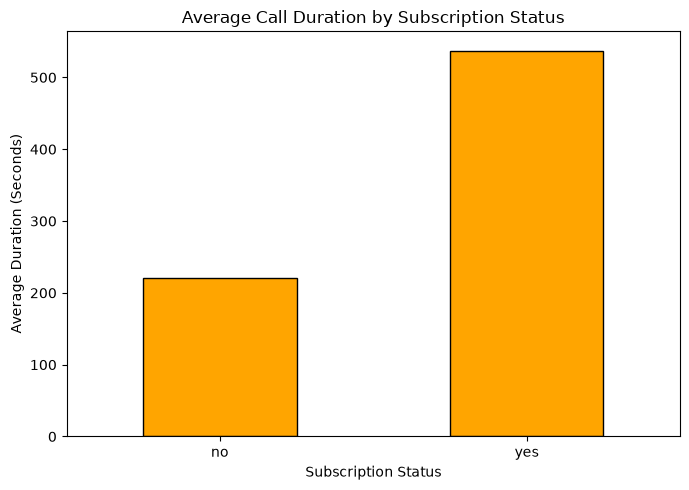

In [40]:
duration_average = df.groupby("y")["duration"].mean()

duration_average.plot(
    kind="bar",
    figsize=(7, 5),
    color="orange",
    edgecolor="black"
)

plt.title("Average Call Duration by Subscription Status")
plt.xlabel("Subscription Status")
plt.ylabel("Average Duration (Seconds)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

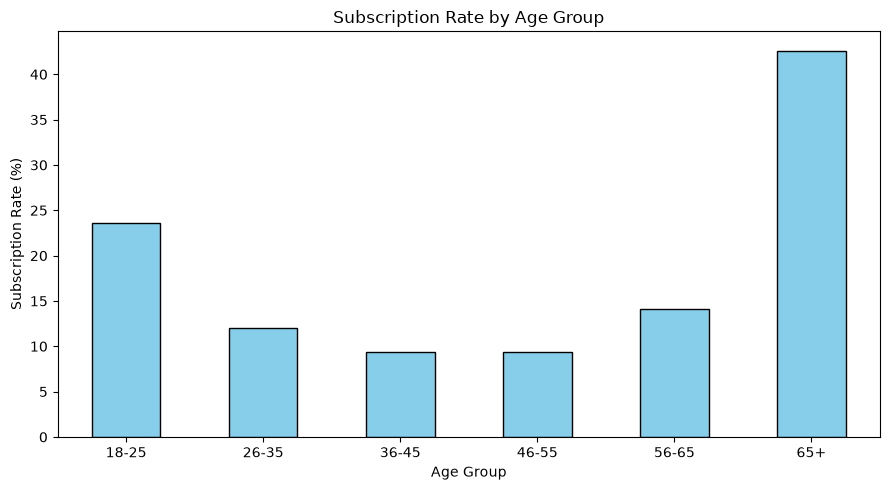

In [41]:
df["age_group"] = pd.cut(
    df["age"],
    bins=[18, 25, 35, 45, 55, 65, 100],
    labels=["18-25", "26-35", "36-45", "46-55", "56-65", "65+"]
)

age_subscription = pd.crosstab(
    df["age_group"],
    df["y"],
    normalize="index"
) * 100

age_subscription["yes"].plot(
    kind="bar",
    figsize=(9, 5),
    color="skyblue",
    edgecolor="black"
)

plt.title("Subscription Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

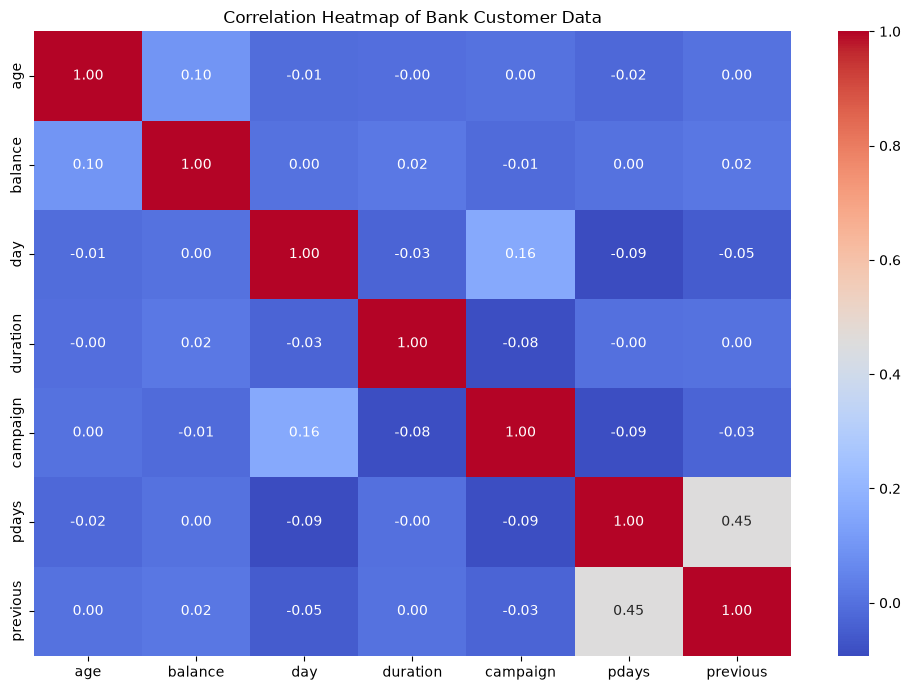

In [42]:
import seaborn as sns

numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Bank Customer Data")
plt.tight_layout()
plt.show()

In [43]:
from scipy.stats import ttest_ind

subscribed_age = df[df["y"] == "yes"]["age"]
not_subscribed_age = df[df["y"] == "no"]["age"]

t_stat, p_value = ttest_ind(
    subscribed_age,
    not_subscribed_age,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("There is a statistically significant difference in average age.")
else:
    print("There is no statistically significant difference in average age.")

T-statistic: 4.318317591167348
P-value: 1.5971046743760392e-05
There is a statistically significant difference in average age.


In [44]:
from scipy.stats import chi2_contingency

contingency_table = pd.crosstab(
    df["housing"],
    df["y"]
)

chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)

if p_value < 0.05:
    print("There is a significant association between housing loan and subscription.")
else:
    print("There is no significant association between housing loan and subscription.")

Chi-square statistic: 874.822448867983
P-value: 2.918797605076633e-192
There is a significant association between housing loan and subscription.


In [45]:
print("BANK CUSTOMER ANALYSIS - EDA SUMMARY")
print("------------------------------------")

print("Total Customers:", len(df))
print("Total Columns:", len(df.columns))

print("Subscribed Customers:", (df["y"] == "yes").sum())
print("Not Subscribed Customers:", (df["y"] == "no").sum())

print("Overall Subscription Rate:",
      round((df["y"] == "yes").mean() * 100, 2), "%")

print("Average Customer Age:", round(df["age"].mean(), 2))
print("Average Account Balance:", round(df["balance"].mean(), 2))
print("Average Campaign Contacts:", round(df["campaign"].mean(), 2))

BANK CUSTOMER ANALYSIS - EDA SUMMARY
------------------------------------
Total Customers: 45211
Total Columns: 18
Subscribed Customers: 5289
Not Subscribed Customers: 39922
Overall Subscription Rate: 11.7 %
Average Customer Age: 40.94
Average Account Balance: 1362.27
Average Campaign Contacts: 2.76


## Key Findings – Bank Customer Analysis

1. The dataset contains 45,211 bank customer records.
2. Only 11.7% of customers subscribed to the term deposit.
3. The average customer age is approximately 40.94 years.
4. Students and retired customers showed higher subscription rates among job categories.
5. Customers without housing loans had a higher subscription rate than customers with housing loans.
6. Customers without personal loans also showed higher subscription rates.
7. Previous successful campaign outcomes were strongly associated with higher subscription rates.
8. The average call duration was higher among customers who subscribed.
9. Statistical testing found a significant difference in average age between subscribers and non-subscribers.
10. Chi-square testing found a significant association between housing loan status and subscription.

### Conclusion

Exploratory Data Analysis revealed several patterns associated with bank term-deposit subscriptions. Customer job, loan status, contact method, campaign history and call duration showed useful differences in subscription rates. These findings can help guide future marketing analysis and customer targeting.